## EU REED

#### 1) Import packages, background databases and set project

In [69]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config

import matplotlib.pyplot as plt
import d3graph
import polyviz

In [70]:
config = Config()

In [71]:
bd.projects.set_current(config.PROJECT_NAME)

In [72]:
import import_db

#### 2) Import foreground database 

In [73]:
bonsai = bd.Database('bonsai_231231')
bonsai_bio = bd.Database('bonsai_231231 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')

In [74]:
bd.databases

Databases dictionary with 4 object(s):
	bonsai_231231
	bonsai_231231 biosphere
	ecoinvent-3.10-biosphere
	reed

In [75]:
from bw2io.importers import ExcelImporter
from reed.utils import Config

importer  = ExcelImporter(config.REED_PATH/'model'/'REED_model_20260203.xlsx',)
importer.match_database(fields=['name','unit','location'])
importer.match_database(db_name=bonsai.name,fields=['name','unit','location','activity type'])
importer.match_database(db_name=bd.config.biosphere,fields=['name','categories','unit'])

Extracted 3 worksheets in 0.43 seconds
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields


In [76]:
importer.statistics()

Graph statistics for `reed` importer:
30 graph nodes:
	None: 30
173 graph edges:
	technosphere: 141
	production: 30
	biosphere: 2
173 edges to the following databases:
	bonsai_231231: 89
	reed: 82
	ecoinvent-3.10-biosphere: 2
0 unique unlinked edges (0 total):




(30, 173, 0, 0)

In [77]:
importer.write_database()

100%|██████████| 30/30 [00:00<00:00, 524.85it/s]


15:50:00+0100 [info     ] Vacuuming database            
Created database: reed


In [78]:
pd.DataFrame(importer.unlinked)

""


In [79]:
reed = bd.Database('reed')

In [80]:
data_reed = [activity.as_dict() for activity in reed]
df_reed = pd.DataFrame(data_reed)


In [81]:
from IPython.display import display
display(df_reed[['code', 'comment', 'location', 'unit', 'database']])

,code,comment,location,unit,database
0,drilling,proxy for drilling. There are multiple differe...,GB,kilogram,reed
1,"machining, generic, kg",to be used as proxy when machining process is ...,GB,kilogram,reed
2,sawing,energy consumption for sawing,DE,hour,reed
3,"machining, generic, hour",to be used as proxy when machining process is ...,GB,hour,reed
4,"flamecutting, natural gas, hour",This process represents flamecutting. The data...,DE,hour,reed
5,sandblasting,0.0266 kg direct CO2 emissions missing due to ...,DE,m2,reed
6,painting,None,DE,m2,reed
7,"soraluce machine, Komatsu","From Soraluce BoM, transport from ES to GB mis...",GB,unit,reed
8,turning,proxy for turning. Water and other liquids for...,GB,kilogram,reed
9,"Soraluce, average",This inventory is calculated based on informat...,GB,unit,reed


In [82]:
bd.databases

Databases dictionary with 4 object(s):
	bonsai_231231
	bonsai_231231 biosphere
	ecoinvent-3.10-biosphere
	reed

#### 3) Select processes to be analysed

In [83]:
lpg = bonsai.get(name = 'Liquefied Petroleum Gases (LPG), combustion of', location = "DE", unit = 'TJ')
steel = bonsai.get(name = 'basic iron and steel and of ferro-alloys and first products thereof', location = "DK", unit = 'tonne')
flamecutting = reed.get(name='flamecutting, lpg, meter', location="DE", unit='meter')
man_welding = reed.get(name='welding, manual', location="GB", unit='hour')
use_case_komatsu = reed.get(name='Komatsu piece', location="GB", unit='unit')

In [84]:
check_activity_type = print(lpg["activity type"])

transforming activity


In [100]:
machining_processes = {
    "man_welding": reed.get(name='welding, manual', location="GB", unit='hour'),
    "rob_welding": reed.get(name='welding, robotic', location="GB", unit='hour'),
    "drilling": reed.get(name='drilling', location="GB", unit='kilogram'),
    "bending": reed.get(name='bending', location="DE", unit='hour'),
    "sawing": reed.get(name='sawing', location="DE", unit='hour'),
    "turning": reed.get(name='turning', location="GB", unit='kilogram'),
    "flamecutting, lpg, meter": reed.get(name='flamecutting, lpg, meter', location="DE", unit='meter'),
    "flamecutting, natural gas,": reed.get(name='flamecutting, natural gas, meter', location="DE", unit='meter'),
    "milling": reed.get(name='milling', location="GB", unit='kilogram'),
}

In [105]:
use_case_machines = {
    "use_case_komatsu": reed.get(name='Komatsu piece', location="GB", unit='unit'),
    "use_case_wwr": reed.get(name='WWR piece', location="DE", unit='unit'),
    "use_case_goimek": reed.get(name='Goimek piece', location="ES", unit='unit'),
}


In [99]:
soraluce_machines = {
"soraluce_komatsu": reed.get(name='soraluce machine, Komatsu', location="GB", unit='unit'),
"soraluce_wwr": reed.get(name='soraluce machine, WWR', location="DE", unit='unit'),  
"soraluce_goimek": reed.get(name='soraluce machine, Goimek', location="ES", unit='unit'),
}

In [111]:
bonsai.search('basic iron and steel gb')

['basic iron and steel and of ferro-alloys and first products thereof' (tonne, GB, None),
 'basic iron and steel and of ferro-alloys and first products thereof' (tonne, GB, None)]

In [88]:
bonsai_bio.search('carbon dioxide')

['carbon dioxide accelerated' (tonne, None, ('air',))]

In [89]:
# export the LCI to Microsoft Excel in an overview format
bi.export.excel.write_lci_excel(bonsai.name, objs=[steel], dirpath=Path.cwd())

'c:\\Users\\TimWeber\\repos_20LCA\\REED\\reed\\scripts\\lci-bonsai_231231.xlsx'

#### 4) Defining LCIA functions

In [90]:
def lca_score(process_dict, method):
    results = []
    for name, process in process_dict.items():
        lca = process.lca(method)
        results.append({
            "Process": name,
            "Location": process.get('location'),
            "Functional Unit": process.get('unit'),
            "Climate Impact (kg CO2eq)": lca.score
        })

    return pd.DataFrame(results)

In [91]:
def run_contribution_analysis(demand_object,
                              lcia_method,
                              max_level=1,
                              cutoff=0.01):
    return bwa.utils.recursive_calculation_to_object(
        demand_object,
        lcia_method=lcia_method,
        max_level=max_level,
        cutoff=cutoff,
        as_dataframe=True,
    )

In [92]:
def plot_contribution(df,
                      title='Contribution Analysis',
                      xlabel='CO2 eq. emissions (kg)',
                      drop_parent=True):
    df_plot = df.copy()

    # Drop the parent (the demand itself)
    if drop_parent:
        # Heuristic: parent is usually the one with maximum score
        parent_score = df_plot['score'].max()
        df_plot = df_plot[df_plot['score'] < parent_score]

    # Sort descending by contribution
    df_plot = df_plot.sort_values(by='score', ascending=False)

    f, ax = plt.subplots(figsize=(5, 2))
    sns.barplot(y='name', x='score', data=df_plot, ax=ax)

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel=''
    )
    plt.tight_layout()
    plt.show()

#### 5) Calculate and present results

In [101]:
df_results = lca_score(machining_processes, config.lcia_gwp100)
display(df_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,man_welding,GB,hour,36.414756
1,rob_welding,GB,hour,49.987530
2,drilling,GB,kilogram,1.123468
3,bending,DE,hour,29.637031
4,sawing,DE,hour,31.313178
5,turning,GB,kilogram,1.531715
6,"flamecutting, lpg, meter",DE,meter,29.883417
7,"flamecutting, natural gas,",DE,meter,29.550113
8,milling,GB,kilogram,1.164053


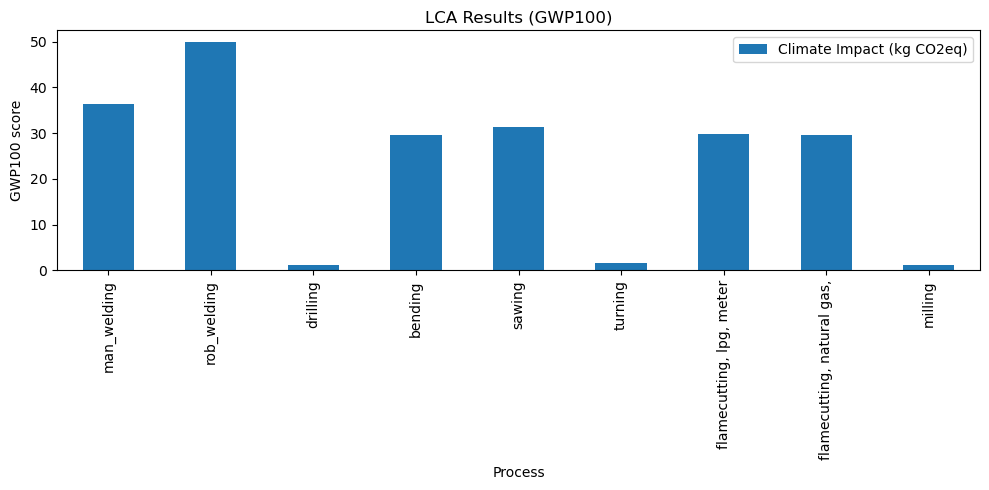

In [102]:
df_plot = df_results.set_index("Process")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Process")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

In [106]:
df_results = lca_score(use_case_machines, config.lcia_gwp100)
display(df_results)

,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,use_case_komatsu,GB,unit,11222.596098
1,use_case_wwr,DE,unit,47171.256387
2,use_case_goimek,ES,unit,22869.389384


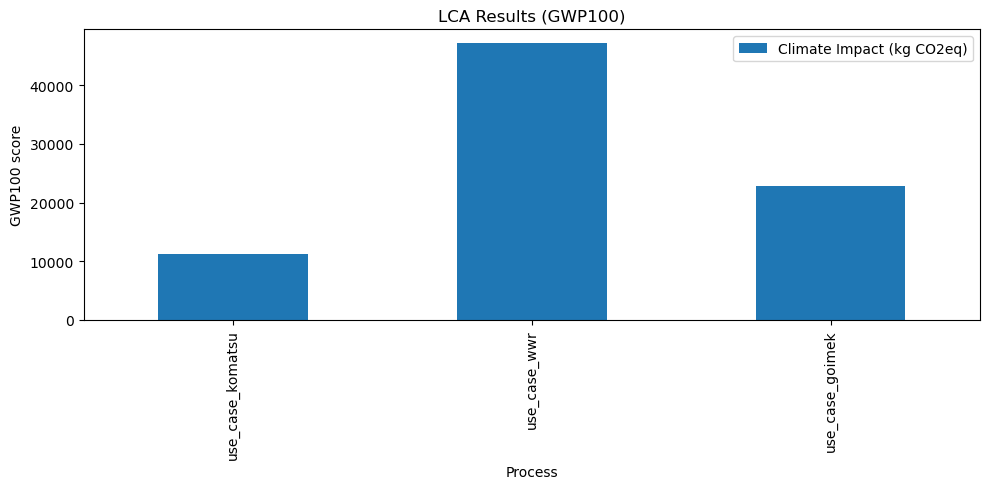

In [107]:
df_plot = df_results.set_index("Process")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Process")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

#### 6) Run contribution analysis

Running contribution analysis: man_welding


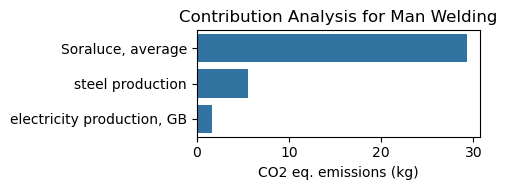

Running contribution analysis: rob_welding


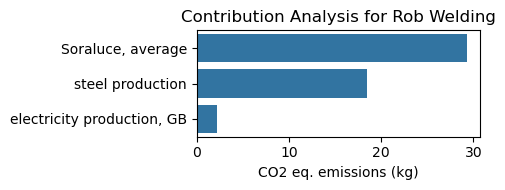

Running contribution analysis: drilling


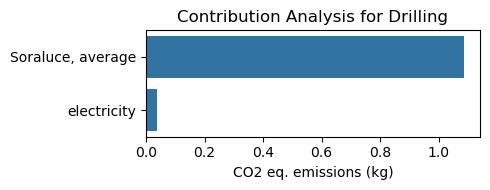

Running contribution analysis: bending


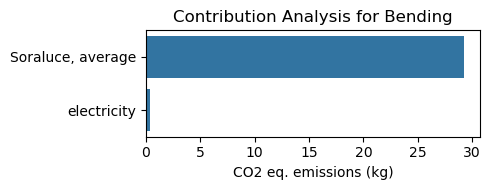

Running contribution analysis: sawing


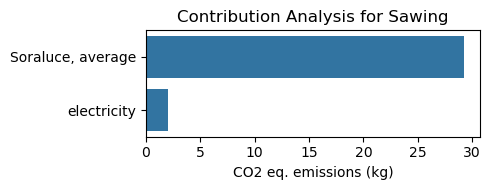

Running contribution analysis: turning


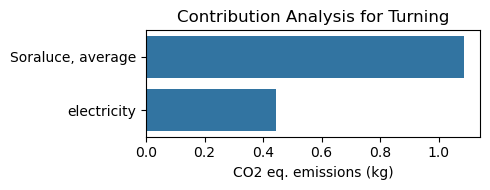

Running contribution analysis: flamecutting, lpg, meter


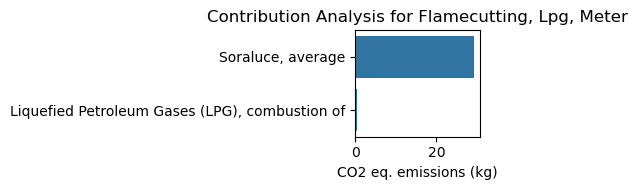

Running contribution analysis: flamecutting, natural gas,


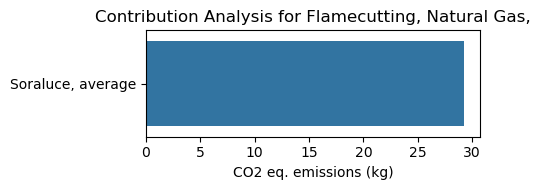

In [97]:
processes_results_ca = {}

for key, demand in machining_processes.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.01
    )
    processes_results_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )

Running contribution analysis: soraluce_komatsu


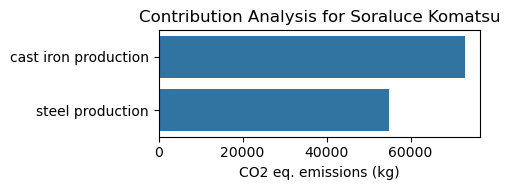

Running contribution analysis: use_case_komatsu


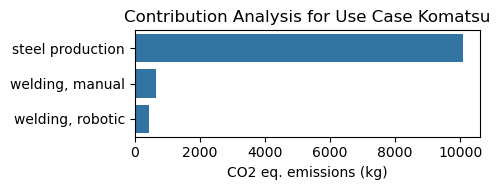

Running contribution analysis: soraluce_wwr


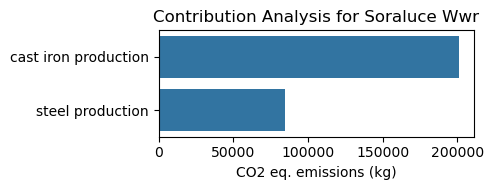

Running contribution analysis: use_case_wwr


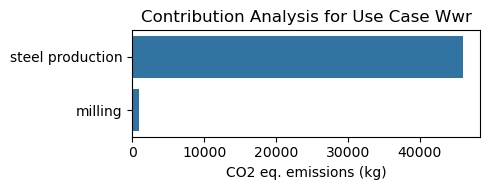

Running contribution analysis: soraluce_goimek


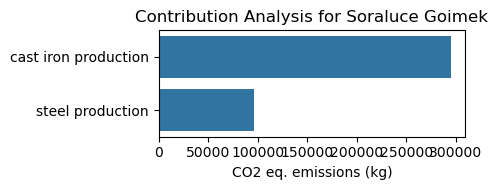

In [98]:
use_case_results_ca = {}

for key, demand in use_case_machines.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.01
    )
    use_case_results_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )